# Introduction to Bayesian Statistics

This notebook serves as teaching material for the introductory class on Bayesian statistics. We will cover:

1. **Beta-Binomial Model** — Understanding priors, likelihoods, and posterior updating
2. **Bayesian Linear Regression** — Estimating regression parameters with uncertainty
3. **Exercises and Discussion Questions** — Practice problems for deepening understanding

We use [PyMC](https://www.pymc.io/) for probabilistic modeling and [ArviZ](https://arviz-devs.github.io/arviz/) for diagnostics and visualization.

In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import pymc as pm
import arviz as az
from scipy import stats

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Plotting style
sns.set_style("whitegrid")
az.style.use("arviz-darkgrid")

print(f"PyMC version: {pm.__version__}")
print(f"ArviZ version: {az.__version__}")

PyMC version: 5.28.0
ArviZ version: 0.23.4


## 1. Beta-Binomial Model

### Conceptual Overview

The **Beta-Binomial model** is the classic introductory example of Bayesian inference. We want to estimate an unknown probability $\theta$ (e.g., the fairness of a coin) from observed binary data.

**The Setup:**
- **Prior:** We express our belief about $\theta$ *before* seeing data using a Beta distribution:

$$\theta \sim \text{Beta}(\alpha, \beta)$$

- **Likelihood:** Given $n$ trials and $y$ successes, the data follows a Binomial distribution:

$$y \mid \theta \sim \text{Binomial}(n, \theta)$$

- **Posterior:** By Bayes' theorem, the posterior is proportional to the likelihood times the prior:

$$p(\theta \mid y) \propto \text{Binomial}(y \mid n, \theta) \cdot \text{Beta}(\theta \mid \alpha, \beta)$$

Because the Beta distribution is a **conjugate prior** for the Binomial likelihood, the posterior has a closed-form solution:

$$\theta \mid y \sim \text{Beta}(\alpha + y, \, \beta + n - y)$$

This means we can verify our MCMC results against the exact analytical solution.

/tmp/ipykernel_30730/1407797396.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


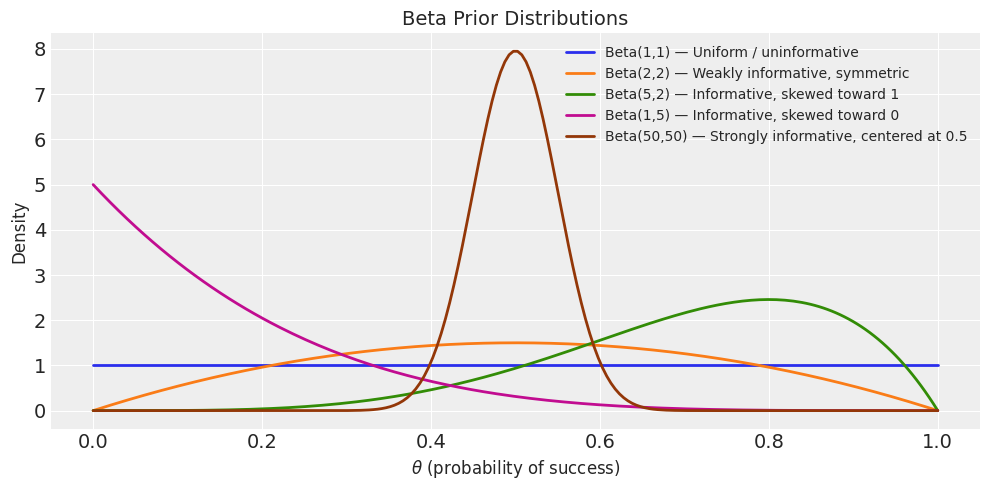

In [2]:
# Visualize different Beta prior distributions
fig, ax = plt.subplots(figsize=(10, 5))
theta_grid = np.linspace(0, 1, 200)

# Different prior parameterizations
priors = [
    (1, 1, "Beta(1,1) — Uniform / uninformative"),
    (2, 2, "Beta(2,2) — Weakly informative, symmetric"),
    (5, 2, "Beta(5,2) — Informative, skewed toward 1"),
    (1, 5, "Beta(1,5) — Informative, skewed toward 0"),
    (50, 50, "Beta(50,50) — Strongly informative, centered at 0.5"),
]

for a, b, label in priors:
    ax.plot(theta_grid, stats.beta.pdf(theta_grid, a, b), label=label, lw=2)

ax.set_xlabel(r"$\theta$ (probability of success)", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.set_title("Beta Prior Distributions", fontsize=14)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [3]:
# Define observed data: coin flips
# Suppose we flip a coin 10 times and observe 7 heads
n_trials = 10
n_successes = 7

# Prior parameters (weakly informative)
alpha_prior = 2
beta_prior = 2

print(f"Observed data: {n_successes} successes out of {n_trials} trials")
print(f"Prior: Beta({alpha_prior}, {beta_prior})")
print(
    f"Analytical posterior: Beta({alpha_prior + n_successes}, {beta_prior + n_trials - n_successes})"
)

Observed data: 7 successes out of 10 trials
Prior: Beta(2, 2)
Analytical posterior: Beta(9, 5)


In [4]:
# Build and sample the Beta-Binomial model with PyMC
with pm.Model() as beta_binomial_model:
    # Prior: Beta distribution for the probability of success
    theta = pm.Beta("theta", alpha=alpha_prior, beta=beta_prior)

    # Likelihood: Binomial distribution for the observed data
    y_obs = pm.Binomial("y_obs", n=n_trials, p=theta, observed=n_successes)

    # Sample from the posterior using MCMC
    trace_bb = pm.sample(2000, tune=1000, random_seed=RANDOM_SEED, cores=2)

# Display model structure
beta_binomial_model

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [theta]


/home/nicolas/git/bayesian-statistics/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 1_000 tune and 2_000 draw iterations (2_000 + 4_000 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


theta ~ Beta(2, 2)
y_obs ~ Binomial(10, theta)

/tmp/ipykernel_30730/2702323454.py:3: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


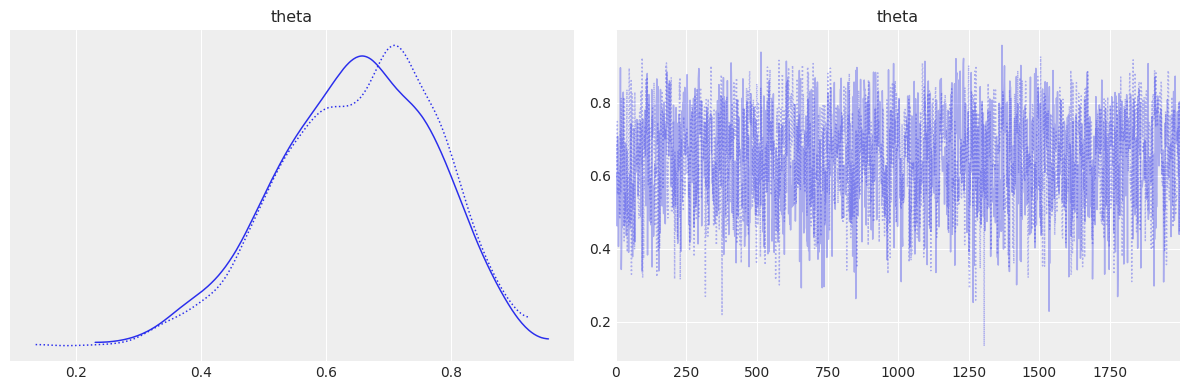

,mean,sd,hdi_3%,hdi_97%
theta,0.648,0.125,0.416,0.873


In [5]:
# ArviZ diagnostics: trace plot and summary
az.plot_trace(trace_bb, figsize=(12, 4))
plt.tight_layout()
plt.show()

# Summary statistics
az.summary(trace_bb, kind="stats", hdi_prob=0.94)

### Visualizing Bayesian Updating: Prior → Likelihood → Posterior

The following plot illustrates the core mechanism of Bayesian inference. We overlay the prior, the (scaled) likelihood, and both the analytical and MCMC-estimated posteriors to see how observed data shifts our beliefs.

/tmp/ipykernel_30730/2255627129.py:44: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


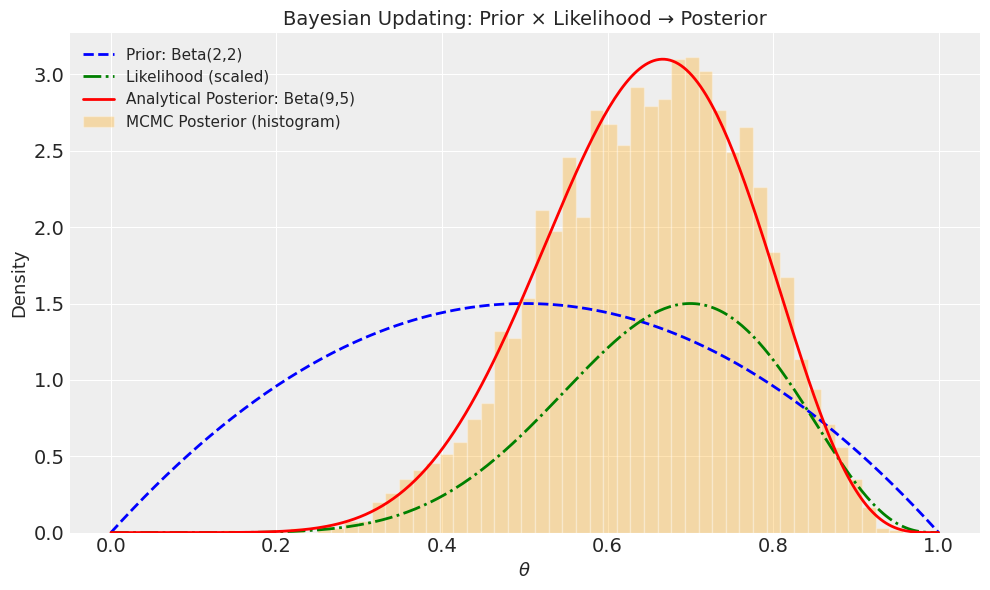

Analytical posterior mean: 0.6429
MCMC posterior mean:       0.6480


In [6]:
# Compare prior, likelihood, and posterior
fig, ax = plt.subplots(figsize=(10, 6))

theta_grid = np.linspace(0, 1, 300)

# Prior
prior_pdf = stats.beta.pdf(theta_grid, alpha_prior, beta_prior)
ax.plot(
    theta_grid, prior_pdf, "b--", lw=2, label=f"Prior: Beta({alpha_prior},{beta_prior})"
)

# Likelihood (scaled for visualization)
likelihood = stats.binom.pmf(n_successes, n_trials, theta_grid)
likelihood_scaled = likelihood / likelihood.max() * prior_pdf.max()
ax.plot(theta_grid, likelihood_scaled, "g-.", lw=2, label="Likelihood (scaled)")

# Analytical posterior
alpha_post = alpha_prior + n_successes
beta_post = beta_prior + n_trials - n_successes
posterior_pdf = stats.beta.pdf(theta_grid, alpha_post, beta_post)
ax.plot(
    theta_grid,
    posterior_pdf,
    "r-",
    lw=2,
    label=f"Analytical Posterior: Beta({alpha_post},{beta_post})",
)

# MCMC posterior (kernel density estimate)
theta_samples = trace_bb.posterior["theta"].values.flatten()
ax.hist(
    theta_samples,
    bins=50,
    density=True,
    alpha=0.3,
    color="orange",
    label="MCMC Posterior (histogram)",
)

ax.set_xlabel(r"$\theta$", fontsize=13)
ax.set_ylabel("Density", fontsize=13)
ax.set_title("Bayesian Updating: Prior × Likelihood → Posterior", fontsize=14)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"Analytical posterior mean: {alpha_post / (alpha_post + beta_post):.4f}")
print(f"MCMC posterior mean:       {theta_samples.mean():.4f}")

/tmp/ipykernel_30730/1637737808.py:4: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


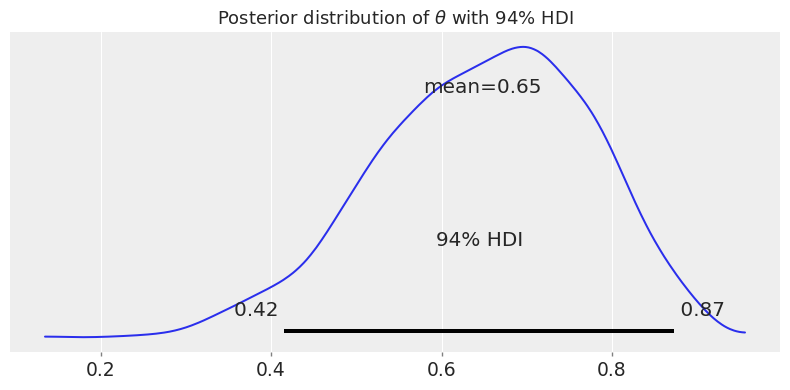

In [7]:
# ArviZ posterior plot with credible interval
az.plot_posterior(trace_bb, var_names=["theta"], hdi_prob=0.94, figsize=(8, 4))
plt.title(r"Posterior distribution of $\theta$ with 94% HDI", fontsize=13)
plt.tight_layout()
plt.show()

### Effect of Prior Strength

An important lesson in Bayesian statistics: **the strength of the prior matters**, especially with small sample sizes. Let's compare what happens when we use a weakly informative vs. a strongly informative prior on the same data.

/tmp/ipykernel_30730/1375444765.py:33: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


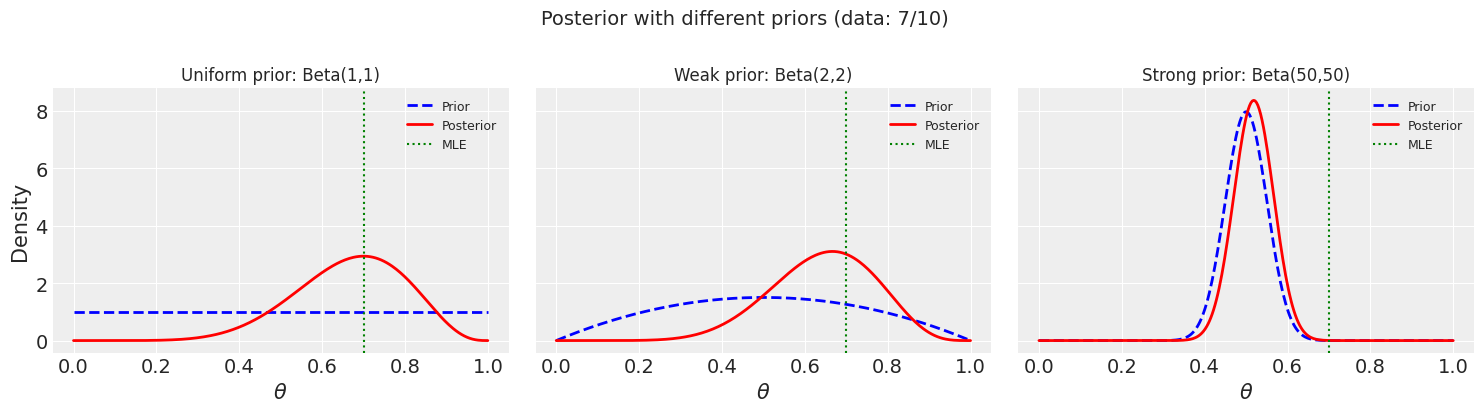

In [8]:
# Compare posteriors under different priors
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

prior_configs = [
    (1, 1, "Uniform prior: Beta(1,1)"),
    (2, 2, "Weak prior: Beta(2,2)"),
    (50, 50, "Strong prior: Beta(50,50)"),
]

for ax, (a, b, title) in zip(axes, prior_configs):
    a_post = a + n_successes
    b_post = b + n_trials - n_successes

    ax.plot(theta_grid, stats.beta.pdf(theta_grid, a, b), "b--", lw=2, label="Prior")
    ax.plot(
        theta_grid,
        stats.beta.pdf(theta_grid, a_post, b_post),
        "r-",
        lw=2,
        label="Posterior",
    )
    ax.axvline(n_successes / n_trials, color="green", ls=":", lw=1.5, label="MLE")
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(r"$\theta$")
    ax.legend(fontsize=9)

axes[0].set_ylabel("Density")
fig.suptitle(
    f"Posterior with different priors (data: {n_successes}/{n_trials})",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

## 2. Bayesian Linear Regression

### Conceptual Overview

In Bayesian linear regression, we model the relationship $y = \alpha + \beta x + \epsilon$ and place **probability distributions on all parameters** rather than computing single point estimates.

**Model specification:**

$$\alpha \sim \mathcal{N}(0, 10) \quad \text{(intercept prior)}$$
$$\beta \sim \mathcal{N}(0, 10) \quad \text{(slope prior)}$$
$$\sigma \sim \text{HalfNormal}(1) \quad \text{(noise std dev prior, constrained positive)}$$
$$y_i \sim \mathcal{N}(\alpha + \beta x_i, \, \sigma) \quad \text{(likelihood)}$$

The output of Bayesian inference is not a single regression line, but a **distribution of plausible regression lines**, capturing our uncertainty about the true relationship.

/tmp/ipykernel_30730/1894315571.py:24: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


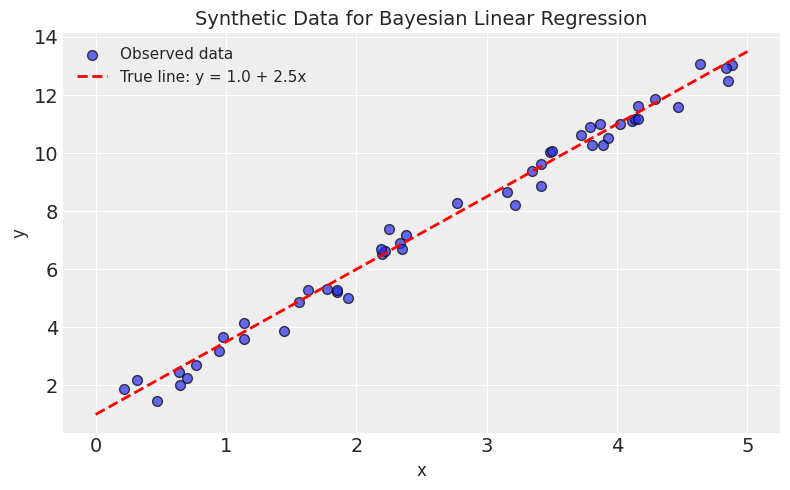

True parameters: intercept=1.0, slope=2.5, sigma=0.5
Number of observations: 50


In [9]:
# Generate synthetic data from a known linear relationship
true_intercept = 1.0
true_slope = 2.5
true_sigma = 0.5
n_obs = 50

x = rng.uniform(0, 5, size=n_obs)
y = true_intercept + true_slope * x + rng.normal(0, true_sigma, size=n_obs)

# Visualize the data
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.7, edgecolors="k", s=50, label="Observed data")
ax.plot(
    [0, 5],
    [true_intercept, true_intercept + true_slope * 5],
    "r--",
    lw=2,
    label=f"True line: y = {true_intercept} + {true_slope}x",
)
ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("y", fontsize=12)
ax.set_title("Synthetic Data for Bayesian Linear Regression", fontsize=14)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(
    f"True parameters: intercept={true_intercept}, slope={true_slope}, sigma={true_sigma}"
)
print(f"Number of observations: {n_obs}")

In [10]:
# Build and sample the Bayesian linear regression model
with pm.Model() as linear_model:
    # Priors
    intercept = pm.Normal("intercept", mu=0, sigma=10)
    slope = pm.Normal("slope", mu=0, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=1)

    # Expected value (deterministic)
    mu = pm.Deterministic("mu", intercept + slope * x)

    # Likelihood
    y_obs = pm.Normal("y_obs", mu=mu, sigma=sigma, observed=y)

    # MCMC sampling
    trace_lr = pm.sample(2000, tune=1000, random_seed=RANDOM_SEED, cores=2)

linear_model

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [intercept, slope, sigma]


/home/nicolas/git/bayesian-statistics/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/nicolas/git/bayesian-statistics/.venv/lib/python3.13/site-packages/pymc/step_methods/hmc/quadpotential.py:316: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)


Sampling 2 chains for 1_000 tune and 2_000 draw iterations (2_000 + 4_000 draws total) took 2 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


intercept ~ Normal(0, 10)
    slope ~ Normal(0, 10)
    sigma ~ HalfNormal(0, 1)
       mu ~ Deterministic(f(intercept, slope))
    y_obs ~ Normal(mu, sigma)

/tmp/ipykernel_30730/3509630318.py:3: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


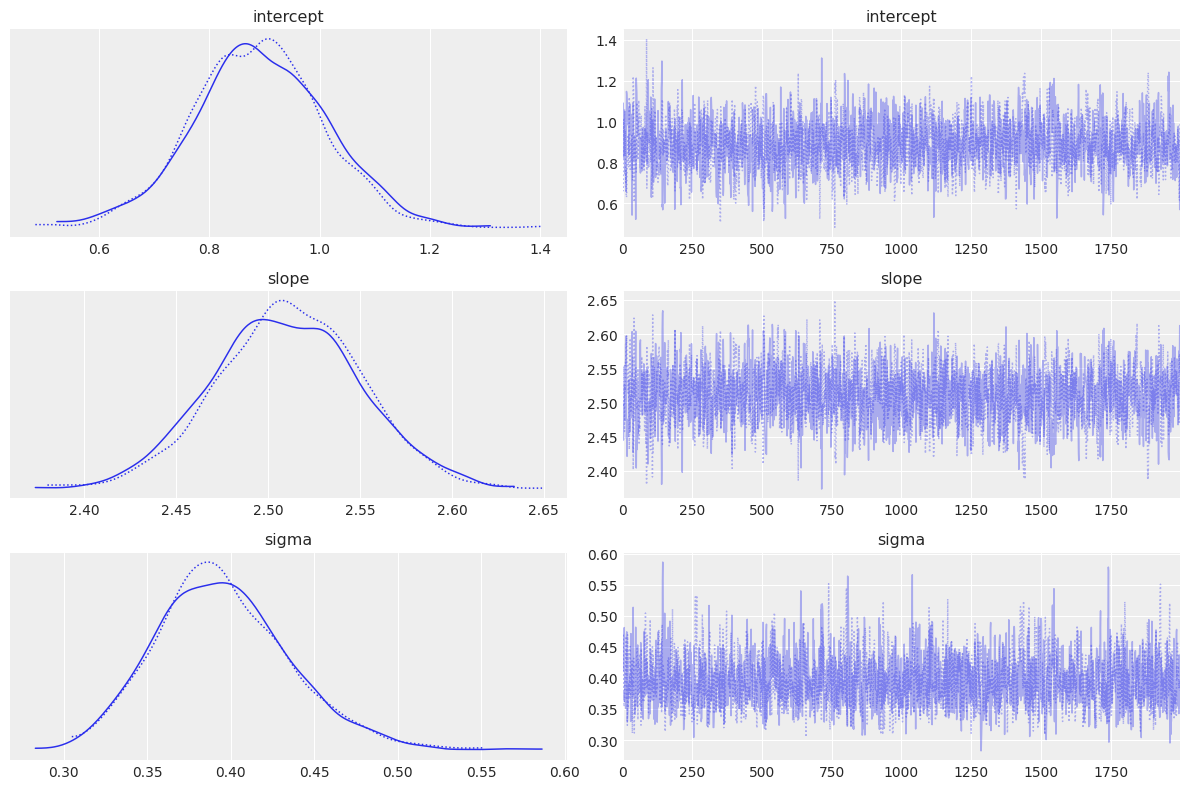

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,0.889,0.119,0.674,1.121,0.003,0.002,1572.0,1738.0,1.0
slope,2.511,0.040,2.439,2.587,0.001,0.001,1737.0,1774.0,1.0
sigma,0.396,0.041,0.323,0.475,0.001,0.001,2179.0,1964.0,1.0


In [11]:
# Trace plots for convergence diagnostics
az.plot_trace(trace_lr, var_names=["intercept", "slope", "sigma"], figsize=(12, 8))
plt.tight_layout()
plt.show()

# Summary statistics with R-hat diagnostics
az.summary(
    trace_lr, var_names=["intercept", "slope", "sigma"], kind="all", hdi_prob=0.94
)

/tmp/ipykernel_30730/145893965.py:12: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


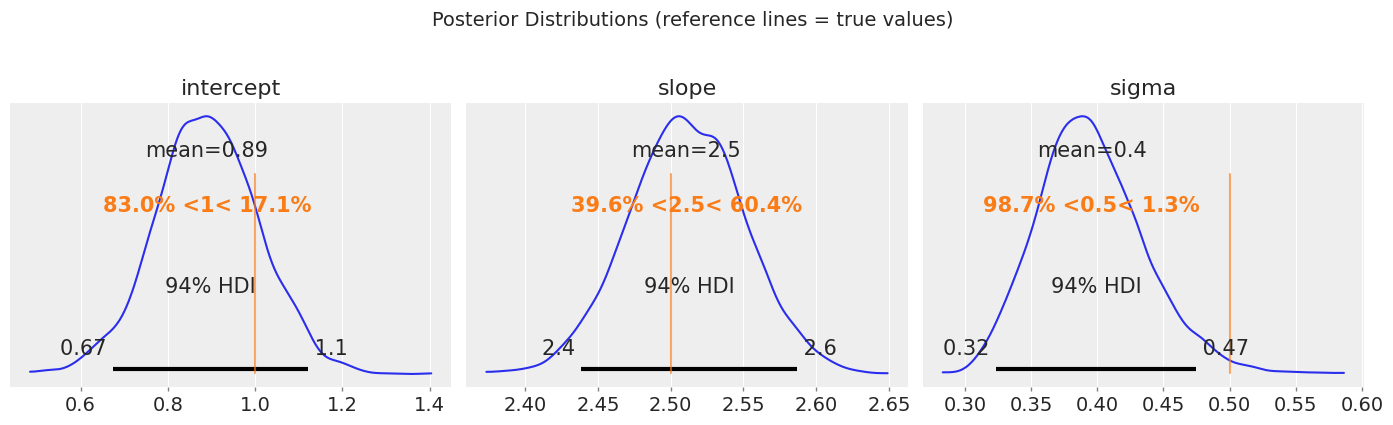

In [12]:
# Posterior distributions of key parameters
az.plot_posterior(
    trace_lr,
    var_names=["intercept", "slope", "sigma"],
    hdi_prob=0.94,
    figsize=(14, 4),
    ref_val=[true_intercept, true_slope, true_sigma],
)
plt.suptitle(
    "Posterior Distributions (reference lines = true values)", fontsize=14, y=1.05
)
plt.tight_layout()
plt.show()

### Posterior Regression Lines and Predictive Uncertainty

A key advantage of Bayesian regression: we can visualize the **uncertainty in our fit** by drawing many plausible regression lines from the posterior, and generate a **posterior predictive distribution** that accounts for both parameter uncertainty and observation noise.

/tmp/ipykernel_30730/2261570098.py:47: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


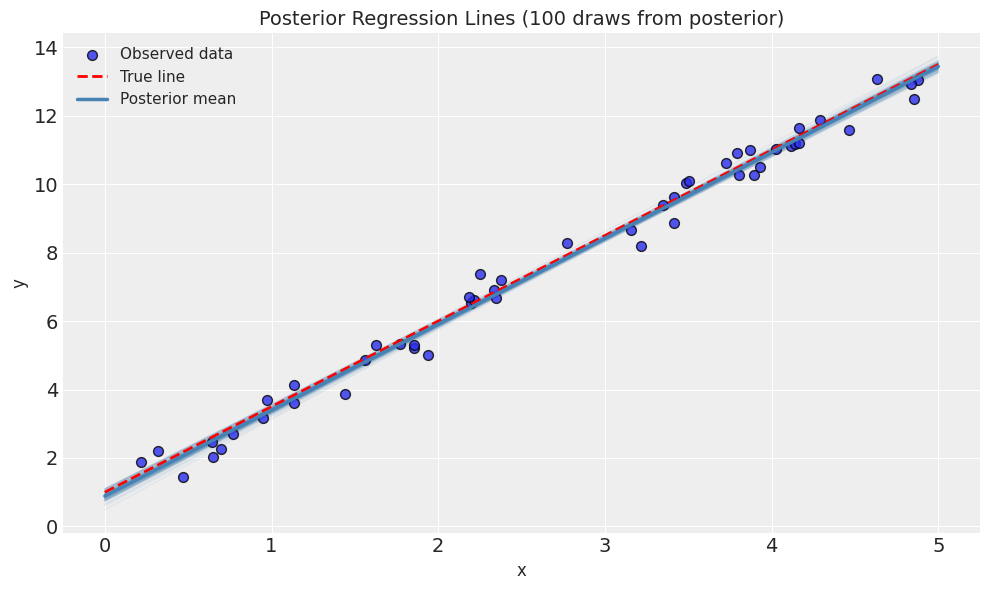

In [13]:
# Plot posterior regression lines
fig, ax = plt.subplots(figsize=(10, 6))

# Extract posterior samples
intercept_samples = trace_lr.posterior["intercept"].values.flatten()
slope_samples = trace_lr.posterior["slope"].values.flatten()

# Plot a subset of posterior regression lines
x_plot = np.linspace(0, 5, 100)
n_lines = 100
idx = rng.choice(len(intercept_samples), size=n_lines, replace=False)

for i in idx:
    ax.plot(
        x_plot,
        intercept_samples[i] + slope_samples[i] * x_plot,
        color="steelblue",
        alpha=0.08,
        lw=1,
    )

# Overlay data and true line
ax.scatter(x, y, alpha=0.8, edgecolors="k", s=50, zorder=5, label="Observed data")
ax.plot(
    x_plot,
    true_intercept + true_slope * x_plot,
    "r--",
    lw=2,
    label="True line",
    zorder=6,
)

# Plot posterior mean line
ax.plot(
    x_plot,
    intercept_samples.mean() + slope_samples.mean() * x_plot,
    "steelblue",
    lw=2.5,
    label="Posterior mean",
    zorder=6,
)

ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("y", fontsize=12)
ax.set_title("Posterior Regression Lines (100 draws from posterior)", fontsize=14)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

Sampling: [y_obs]


/home/nicolas/git/bayesian-statistics/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/tmp/ipykernel_30730/1807495308.py:44: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


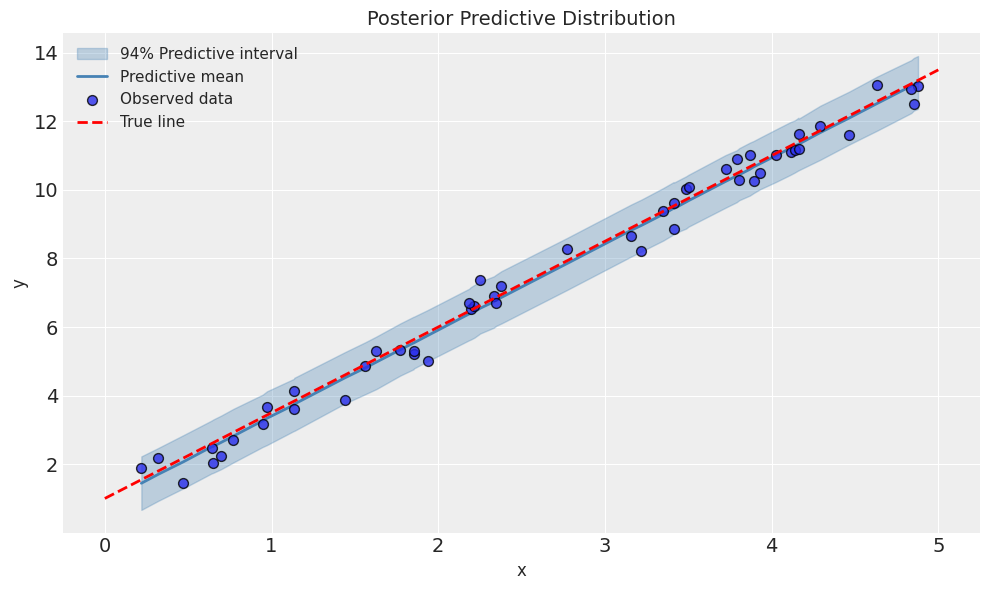

In [14]:
# Posterior predictive check
with linear_model:
    ppc = pm.sample_posterior_predictive(trace_lr, random_seed=RANDOM_SEED)

# Plot posterior predictive distribution with credible bands
fig, ax = plt.subplots(figsize=(10, 6))

# Compute mean prediction and credible bands at each x
x_sort_idx = np.argsort(x)
x_sorted = x[x_sort_idx]
y_sorted = y[x_sort_idx]

# Get posterior predictive samples for each observation
ppc_samples = ppc.posterior_predictive["y_obs"].values.reshape(-1, n_obs)

# Compute HDI bands
ppc_mean = ppc_samples.mean(axis=0)[x_sort_idx]
ppc_hdi_low = np.percentile(ppc_samples, 3, axis=0)[x_sort_idx]
ppc_hdi_high = np.percentile(ppc_samples, 97, axis=0)[x_sort_idx]

ax.fill_between(
    x_sorted,
    ppc_hdi_low,
    ppc_hdi_high,
    alpha=0.3,
    color="steelblue",
    label="94% Predictive interval",
)
ax.plot(x_sorted, ppc_mean, "steelblue", lw=2, label="Predictive mean")
ax.scatter(x, y, alpha=0.8, edgecolors="k", s=50, zorder=5, label="Observed data")
ax.plot(
    x_plot,
    true_intercept + true_slope * x_plot,
    "r--",
    lw=2,
    label="True line",
    zorder=6,
)

ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("y", fontsize=12)
ax.set_title("Posterior Predictive Distribution", fontsize=14)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

## 3. Exercises and Discussion Questions

Use these questions to review your understanding of the material covered in this notebook. Some are conceptual, and others ask you to modify the code above.

---

### Conceptual Questions

**Q1.** What is the difference between a frequentist and a Bayesian approach to statistics? How does each framework interpret the concept of "probability"?

**Q2.** Explain the concept of **conjugacy**. Why is the Beta distribution a conjugate prior for the Binomial likelihood? What is the practical advantage of conjugacy?

**Q3.** In the linear regression model, what does the **posterior distribution** of the slope tell us that a single point estimate (e.g., OLS) does not?

**Q4.** What are **credible intervals** (HDI), and how do they differ from frequentist **confidence intervals**? Which interpretation do you find more intuitive, and why?

**Q5.** What is the role of **Markov Chain Monte Carlo (MCMC)** in Bayesian inference? Why is it needed when we move beyond simple conjugate models?

**Q6.** How can you diagnose whether the MCMC sampler has **converged**? Name at least two diagnostics you would check (hint: look at the ArviZ summary output).

---